---
title: "Practice Activity 9-2"
author: "Patrick Mori"

format:
  html:
    theme: minty
    toc: true
execute:
  echo: true
embed-resources: true

---


# Training and Test Errors, Cross-Validation, Pipelines

In [1]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [2]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [3]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [4]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 118.1 ,-29994.96, 26728.53, 1271.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.694e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


1. Explain conceptually what the "fit" step does. What is the output?

The fit step uses the training data to estimate the intercept and coefficients that minimize the sum of squared residuals. Its output is a fitted LinearRegression object containing the learned model parameters. It does not produce predictions until .predict() is called.

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

First, use the fitted model to predict SalePrice for every observation in X_train. Then calculate each residual, square the residuals, average the squared residuals, and take the square root.

3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

The training RMSE is approximately $51,350. This means that the model’s predictions for the training houses typically differ from their actual sale prices by about $51,350. Whether this is large depends on the scale of house prices. A useful benchmark is a baseline model that always predicts the mean sale price. Its RMSE is approximately $79,873, so this regression model improves substantially over the baseline, although its errors are still fairly large.

4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

Adding another feature cannot increase the training RMSE for ordinary least-squares regression. The larger model could always assign the new feature a coefficient of zero and reproduce the smaller model, so its training RMSE must stay the same or decrease. Comparing the models using training RMSE is not useful because training error automatically favors more flexible models and does not show how well they will predict new houses.

5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

The training RMSE should be 0, assuming there are no complications from identical predictor values with different outcomes. Each training observation is its own nearest neighbor, so the model predicts its observed sale price exactly.

6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

The training RMSE generally increases as \(k\) increases. With a larger \(k\), each prediction is averaged across more neighboring observations, so the model becomes smoother and fits the individual training observations less closely. The increase does not have to be strictly monotonic for every possible dataset.

7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

True test RMSE concerns predictions for new observations that were not used to fit or select the model. In practice, the outcomes for future houses are not yet available, so their prediction errors cannot be calculated directly. Once a dataset is repeatedly used to develop or select a model, it is no longer a completely independent test set. Therefore, we must estimate test error using methods such as cross-validation.

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

In \(k\)-fold cross-validation, the data are divided into \(k\) folds. The model is fitted on \(k-1\) folds and evaluated on the remaining fold. This process is repeated so that every fold serves as the validation fold once. Because each prediction is made by a model that was not trained on that observation, the combined validation errors approximate errors on new data. The squared errors are averaged and square-rooted to estimate test RMSE.

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

The test RMSE should generally be greater than the training RMSE because the model was optimized to fit the training observations. Using 10-fold cross-validation, the estimated test RMSE is approximately $52,093, compared with a training RMSE of approximately $51,350. Thus, the cross-validation RMSE is slightly larger, as expected.

10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

Adding predictors does not necessarily decrease test RMSE. Additional predictors may contain useful information, but irrelevant or redundant predictors can increase model variance and hurt performance on new data. With "TotRms AbvGrd" added, the 10-fold cross-validation RMSE is approximately $52,214, compared with $52,093 for the original model. Therefore, the original model is slightly better according to cross-validation, although the difference is small.

11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath','Neighborhood']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [6]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(neighborhood_model,
                         X = X_train,
                         y = y_train,
                         scoring="neg_mean_squared_error",
                         cv=10)
scores

/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 461, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 97, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/opt/anaco

array([-1.44545960e+09, -2.17595046e+09, -1.03959067e+09, -1.75337711e+09,
       -1.09461091e+09, -2.46145139e+09, -1.41979799e+09, -2.32075542e+09,
       -1.21633488e+09,             nan])

11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

Standardizing the predictors would change the numerical values and interpretation of the coefficients. Each slope would describe the expected change in sale price associated with a one-standard-deviation increase in that predictor, and the intercept would also change because the predictors are centered. However, unregularized linear regression would produce the same fitted values, so the training RMSE would not change.

12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

During cross-validation, the scaler must be fitted separately using only the training portion of each fold. The means and standard deviations learned from that training portion are then used to transform both the training fold and its validation fold. Including standardization in the pipeline makes this happen automatically. If the entire dataset were standardized before cross-validation, information from the validation folds would leak into the training process, potentially producing an overly optimistic estimate of test performance.

## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

,Absolute correlation with SalePrice
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974
Garage Yr Blt,0.526965


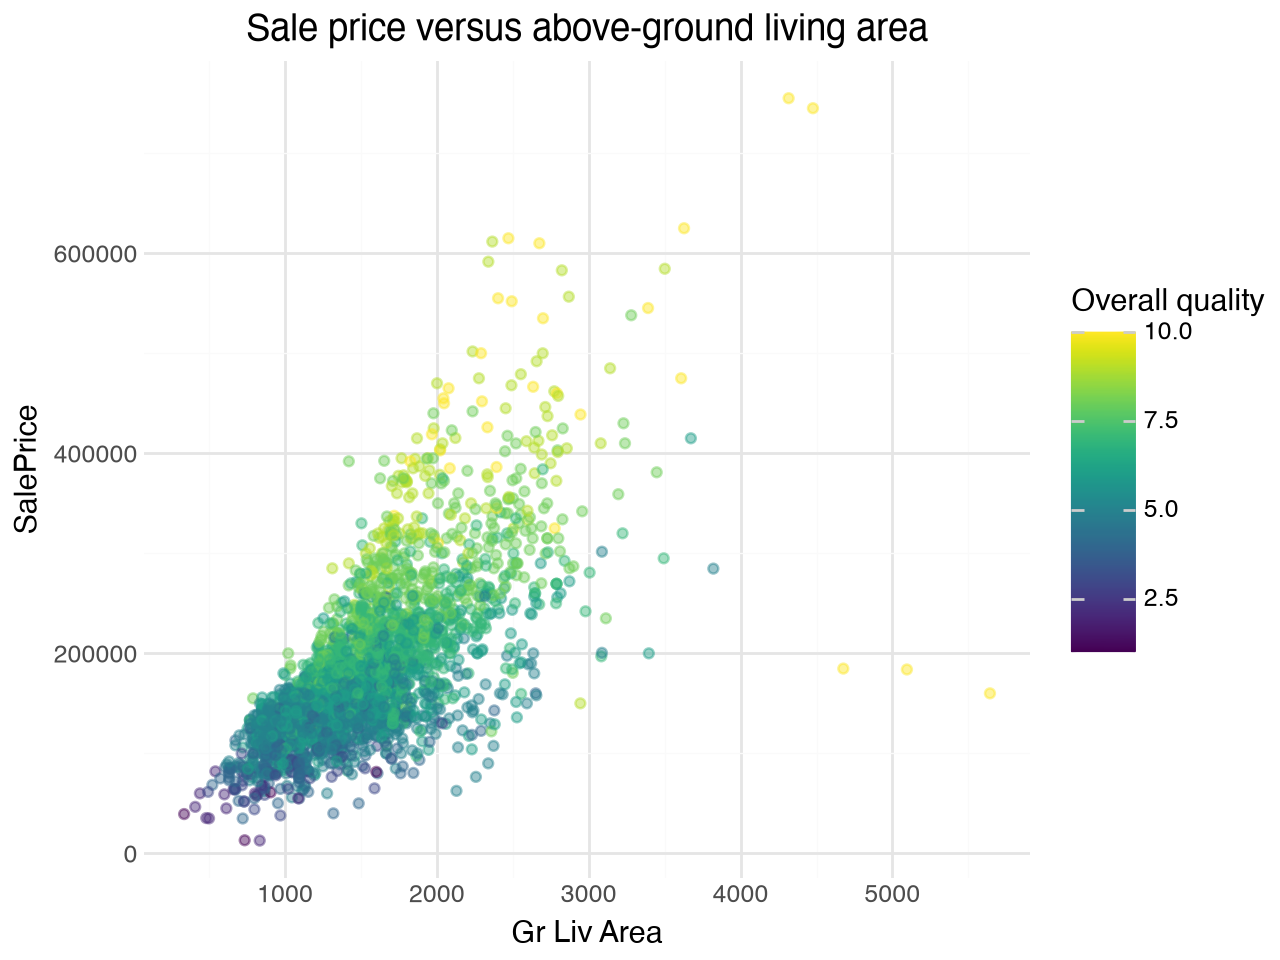

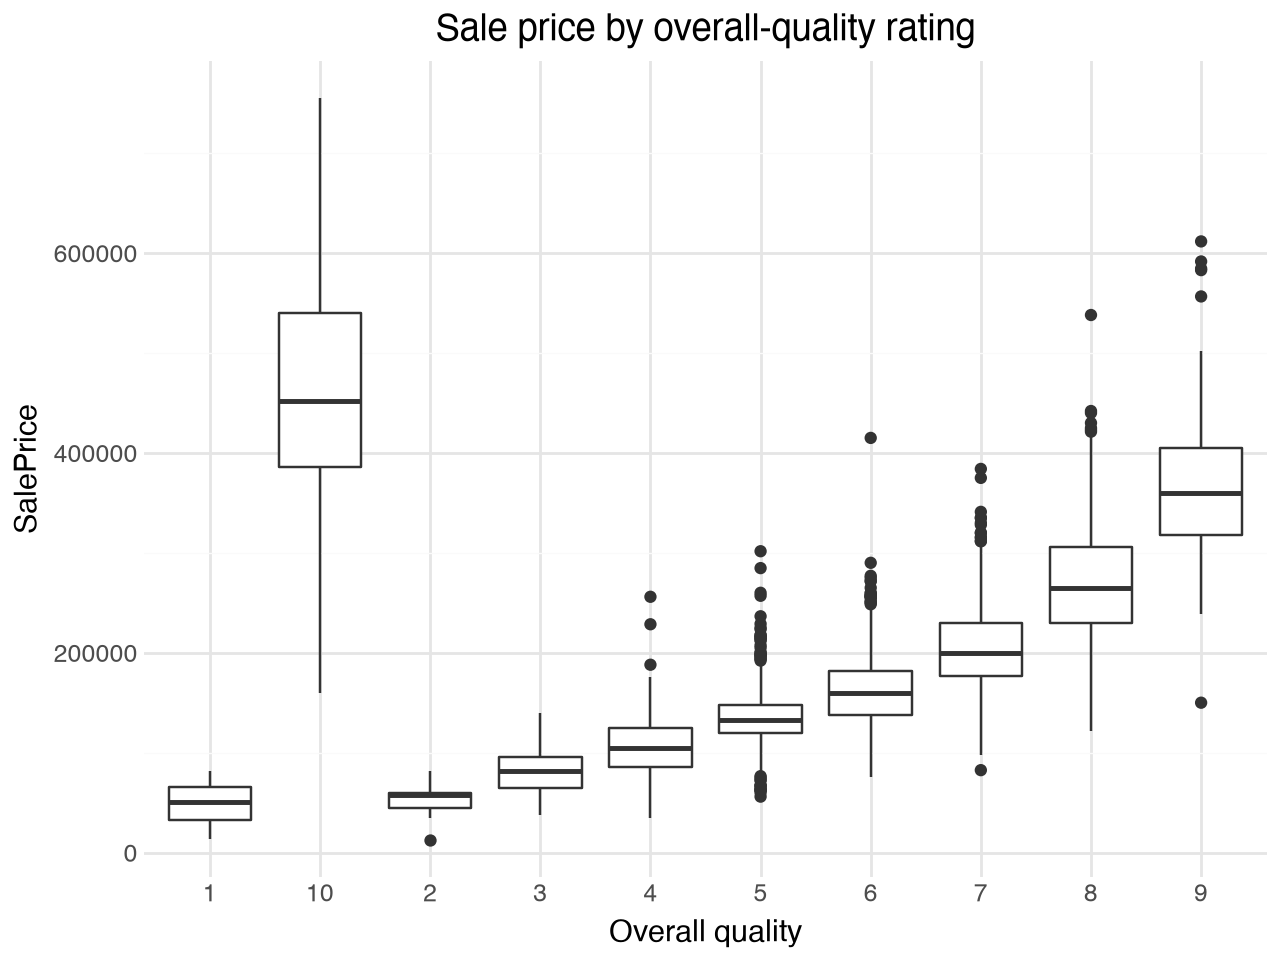

,Model,CV RMSE,SD of fold RMSE
0,Linear: degree-2 polynomial/interactions,"$28,042","$6,325"
1,Linear: expanded numeric + categorical,"$30,491","$8,403"
2,KNN: k=10,"$31,785","$7,183"
3,KNN: k=20,"$31,829","$7,257"
4,KNN: k=5,"$32,183","$6,640"
5,Decision tree: depth=8,"$34,071","$5,421"
6,Decision tree: depth=6,"$36,003","$5,614"
7,Decision tree: depth=unrestricted,"$37,540","$6,385"
8,Decision tree: depth=4,"$41,971","$7,777"
9,Linear: original predictors,"$52,093","$8,568"


Best model: Linear: degree-2 polynomial/interactions
Estimated test RMSE: $28,041.80


In [7]:
# Explore the outcome and some promising predictors.
from IPython.display import display

numeric_correlations = (
    df_ames.select_dtypes(include=np.number)
    .corr()["SalePrice"]
    .drop(["SalePrice", "Order", "PID"])
    .abs()
    .sort_values(ascending=False)
    .head(10)
)
display(numeric_correlations.to_frame("Absolute correlation with SalePrice"))

plot_df = df_ames.assign(OverallQual=df_ames["Overall Qual"].astype(str))
display(
    ggplot(plot_df, aes(x="Gr Liv Area", y="SalePrice", color="Overall Qual"))
    + geom_point(alpha=0.45)
    + labs(title="Sale price versus above-ground living area", color="Overall quality")
    + theme_minimal()
)
display(
    ggplot(plot_df, aes(x="OverallQual", y="SalePrice"))
    + geom_boxplot()
    + labs(title="Sale price by overall-quality rating", x="Overall quality")
    + theme_minimal()
)

# Compare several model families using the same 10-fold CV procedure.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

X = df_ames.drop(columns="SalePrice")
y = df_ames["SalePrice"]

basic_numeric = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
selected_numeric = [
    "Overall Qual", "Gr Liv Area", "Garage Cars", "Garage Area",
    "Total Bsmt SF", "1st Flr SF", "Year Built", "Year Remod/Add",
    "Full Bath", "TotRms AbvGrd", "Fireplaces", "Mas Vnr Area",
    "BsmtFin SF 1", "Lot Area", "Wood Deck SF", "Open Porch SF",
]
selected_categorical = [
    "Neighborhood", "Exter Qual", "Kitchen Qual", "Bsmt Qual",
    "Garage Finish", "Foundation", "MS Zoning", "Sale Condition",
]
polynomial_numeric = [
    "Overall Qual", "Gr Liv Area", "Garage Cars", "Total Bsmt SF",
    "Year Built", "Year Remod/Add", "1st Flr SF", "Garage Area",
    "Full Bath", "Fireplaces",
]

numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("dummify", OneHotEncoder(handle_unknown="ignore")),
])

basic_preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, basic_numeric),
])
numeric_preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, selected_numeric),
])
mixed_preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, selected_numeric),
    ("categorical", categorical_steps, selected_categorical),
])
polynomial_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("standardize", StandardScaler()),
])
polynomial_preprocessor = ColumnTransformer([
    ("polynomial_numeric", polynomial_steps, polynomial_numeric),
    ("categorical", categorical_steps, selected_categorical),
])

candidate_models = {
    "Linear: original predictors": Pipeline([
        ("preprocessing", basic_preprocessor),
        ("model", LinearRegression()),
    ]),
    "Linear: expanded numeric + categorical": Pipeline([
        ("preprocessing", mixed_preprocessor),
        ("model", LinearRegression()),
    ]),
    "Linear: degree-2 polynomial/interactions": Pipeline([
        ("preprocessing", polynomial_preprocessor),
        ("model", LinearRegression()),
    ]),
}

for k in [5, 10, 20]:
    candidate_models[f"KNN: k={k}"] = Pipeline([
        ("preprocessing", numeric_preprocessor),
        ("model", KNeighborsRegressor(n_neighbors=k)),
    ])

for depth in [4, 6, 8, None]:
    depth_label = "unrestricted" if depth is None else str(depth)
    candidate_models[f"Decision tree: depth={depth_label}"] = Pipeline([
        ("preprocessing", mixed_preprocessor),
        ("model", DecisionTreeRegressor(max_depth=depth, random_state=42)),
    ])

results = []
for name, model in candidate_models.items():
    fold_mse = -cross_val_score(
        model, X, y, scoring="neg_mean_squared_error", cv=10, n_jobs=-1
    )
    results.append({
        "Model": name,
        "CV RMSE": np.sqrt(fold_mse.mean()),
        "SD of fold RMSE": np.sqrt(fold_mse).std(ddof=1),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("CV RMSE")
    .reset_index(drop=True)
)
display(results_df.style.format({"CV RMSE": "${:,.0f}", "SD of fold RMSE": "${:,.0f}"}))

best_name = results_df.loc[0, "Model"]
best_rmse = results_df.loc[0, "CV RMSE"]
best_model = candidate_models[best_name].fit(X, y)
print(f"Best model: {best_name}")
print(f"Estimated test RMSE: ${best_rmse:,.2f}")
